# Chapter 4, Techniques of Circuit Analysis, on One Circuit: an 8-bit R-2R DAC

**Colin Casey, 2026.** Nilsson & Riedel, *Electric Circuits*, Ch. 4. Library: `dgs/circuit_techniques_ch4.py` (tests: `tests/test_circuit_techniques_ch4.py`). Built on `dgs/spice.py` (MNA) and `dgs/circuit_terminology.py` (Table 4.1, node and mesh methods in SymPy).

## In plain words

An **R-2R ladder** turns an 8-bit number into a voltage using only two resistor values, $R$ and $2R$. Loop the code from $2^0$ to $2^8$ and every technique in Chapter 4 has a job:

| Ch. 4 section | job in this notebook |
|---|---|
| 4.1 Terminology | count nodes, essential nodes and meshes of the ladder |
| 4.2–4.4 Node-voltage method | solve the ladder for all 256 codes (MNA) |
| 4.5–4.8 Mesh-current method; node vs mesh | solve a small ladder both ways; compare equation counts as bits grow |
| 4.3/4.6 Dependent sources | the op-amp output buffer, a VCVS with finite gain |
| 4.9 Source transformations | Thévenin ↔ Norton, checked with a load sweep |
| 4.10–4.11 Thévenin and Norton | $R_\text{th}=R$ for *every* code |
| 4.12 Maximum power transfer | the load that takes the most power |
| 4.13 Superposition | each bit alone; the sum is the answer |
| Practical Perspective: realistic resistors | tolerance → DNL/INL, monotonicity |

Plus the bench: **room temperature** (Johnson noise, tempco), a **function generator** (a 50 Ω Thévenin source), and an **oscilloscope** (1 MΩ ∥ 15 pF, a load on whatever it measures).

Assumed values: $R=10$ kΩ, $V_\text{ref}=3.3$ V, so 1 LSB $=3.3/256=12.9$ mV. Kernel: **py312**.

In [1]:
import numpy as np
import sympy as sp
sp.init_printing()
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs import circuit_techniques_ch4 as c
from dgs import circuit_terminology as ct
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
N, R, VREF = 8, 10e3, 3.3
LSB = VREF / 2**N

## 1. The ladder, solved by the node-voltage method for every code (Fig. 1)

Each bit's $2R$ leg connects to $V_\text{ref}$ (bit = 1) or ground (bit = 0). MNA writes KCL at every node, with one extra unknown for the reference source's current, and solves all node voltages at once. The loop "from $2^0$ to $2^8$" also shows a classic off-by-one: $2^8=256$ is *one past* the largest 8-bit code.

max |MNA - ideal V_ref*code/256| over all 256 codes: 8.9e-16 V


,k,code,binary,V_out,ideal
0,0,1,00000001,0.012891,0.012891
1,1,2,00000010,0.025781,0.025781
2,2,4,00000100,0.051562,0.051562
3,3,8,00001000,0.103125,0.103125
4,4,16,00010000,0.206250,0.206250
5,5,32,00100000,0.412500,0.412500
6,6,64,01000000,0.825000,0.825000
7,7,128,10000000,1.650000,1.650000
8,8,256,100000000 (9 bits!),NaN,NaN


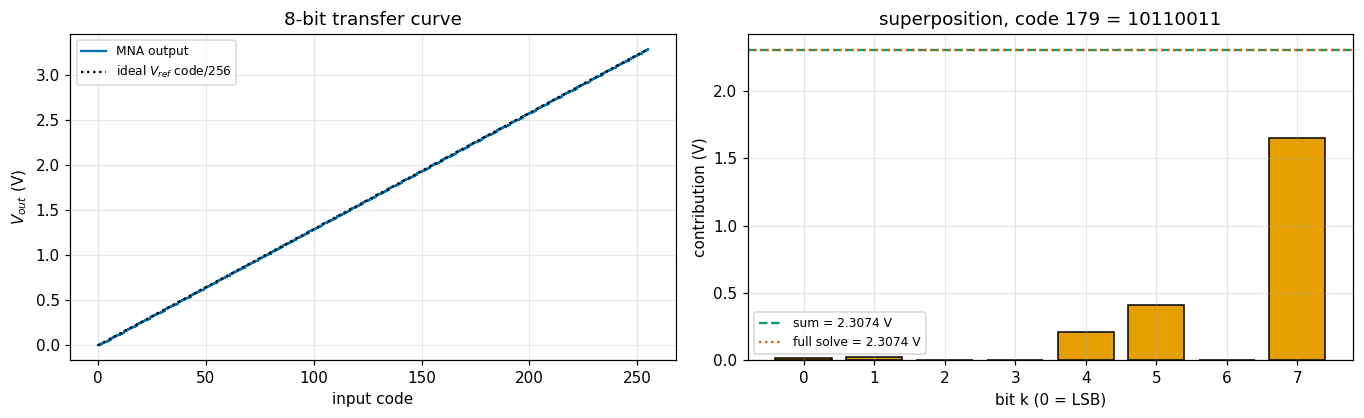

Figure 1. Left: the DAC staircase from the node-voltage (MNA) solution (solid blue steps) on the ideal line (dotted black). Right: superposition for code 10110011. Each set bit acting alone (orange bars; grey = bit off) contributes V_ref 2^k / 256; their sum (dashed green) equals the full solve (dotted red). Note the bars double with k but only look large for the top bits: the MSB alone gives half of V_ref.


In [2]:
curve = c.transfer_curve(N, R, VREF)
print(f'max |MNA - ideal V_ref*code/256| over all 256 codes: {np.max(np.abs(curve - c.ideal_output(np.arange(256)))):.1e} V')
rows = []
for k in range(0, 9):
    code_ = 2**k
    if code_ < 2**N:
        rows.append(dict(k=k, code=code_, binary=format(code_, '08b'), V_out=c.dac_output(code_), ideal=c.ideal_output(code_)))
    else:
        rows.append(dict(k=k, code=code_, binary=format(code_, 'b') + ' (9 bits!)', V_out=np.nan, ideal=np.nan))
display(pd.DataFrame(rows))
code0 = 0b10110011
parts = c.superposition_bits(code0)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
ax[0].step(np.arange(256), curve, where='post', color=OI['blue'], label='MNA output')
ax[0].plot(np.arange(256), c.ideal_output(np.arange(256)), ':', color=OI['black'], label='ideal $V_{ref}$ code/256')
ax[0].set(xlabel='input code', ylabel='$V_{out}$ (V)', title='8-bit transfer curve'); ax[0].legend(fontsize=8)
ax[1].bar(range(N), parts, color=[OI['orange'] if p_ else '0.85' for p_ in parts], edgecolor=OI['black'])
ax[1].axhline(sum(parts), color=OI['green'], ls='--', label=f'sum = {sum(parts):.4f} V')
ax[1].axhline(c.dac_output(code0), color=OI['red'], ls=':', label=f'full solve = {c.dac_output(code0):.4f} V')
ax[1].set(xlabel='bit k (0 = LSB)', ylabel='contribution (V)', title=f'superposition, code {code0} = {code0:08b}'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 1. Left: the DAC staircase from the node-voltage (MNA) solution (solid blue steps) on the ideal line (dotted black). '
      f'Right: superposition for code {code0:08b}. Each set bit acting alone (orange bars; grey = bit off) contributes '
      'V_ref 2^k / 256; their sum (dashed green) equals the full solve (dotted red). Note the bars double with k but only '
      'look large for the top bits: the MSB alone gives half of V_ref.')

## 2. Node-voltage vs mesh-current (4.1, 4.5–4.8)

The SymPy solvers from `circuit_terminology` write the equations both ways for a 2-bit ladder (code 11, $V_\text{ref}=1$ V, $R=1$ Ω) and agree branch for branch. Then the counting rules decide which method is cheaper as the ladder grows.

In [3]:
els2 = [('Vr', 'ref', '0', 'V', 1), ('R0', 'n1', 'ref', 'R', 2), ('R1', 'n2', 'ref', 'R', 2), ('Rs', 'n1', 'n2', 'R', 1), ('Rt', 'n1', '0', 'R', 2)]
eq_n, cur_n, volt_n = ct.node_voltage_solution(els2)
eq_m, cur_m = ct.mesh_current_solution(els2)
print('node-voltage equations:'); [display(e_) for e_ in eq_n]
print('mesh-current equations:'); [display(e_) for e_ in eq_m]
print('branch currents agree:', all(sp.simplify(cur_n[k] - cur_m[k]) == 0 for k in cur_n))
def ct_ladder(n_bits, code_):
    els = [('Vr', 'ref', '0', 'V', 1)]
    for k in range(n_bits):
        els.append((f'L{k}', f'n{k}', 'ref' if (code_ >> k) & 1 else '0', 'R', 2))
    for k in range(n_bits - 1):
        els.append((f'S{k}', f'n{k}', f'n{k+1}', 'R', 1))
    els.append(('T', 'n0', '0', 'R', 2))
    return els
cnt = []
for nb in range(2, 9):
    t41 = ct.table_4_1(ct_ladder(nb, int('10' * 8, 2) & (2**nb - 1)))
    cnt.append(dict(bits=nb, nodes=t41['n (nodes)'], essential_nodes=t41['n_e (essential nodes)'],
                    node_voltage_eqs=t41['KCL equations n_e - 1'], mesh_eqs=t41['meshes'], essential_branches=t41['b_e (essential branches)']))
pd.DataFrame(cnt)

node-voltage equations:


mesh-current equations:


branch currents agree: True


,bits,nodes,essential_nodes,node_voltage_eqs,mesh_eqs,essential_branches
0,2,4,2,1,2,3
1,3,5,3,2,3,5
2,4,6,5,4,4,8
3,5,7,6,5,5,10
4,6,8,7,6,6,12
5,7,9,8,7,7,14
6,8,10,9,8,8,16


For the ladder both counts grow by about one per bit, so neither method wins outright. In practice the node-voltage method generalizes better (MNA is what SPICE uses) because it handles current sources and non-planar circuits without supermeshes.

## 3. Thévenin, Norton, source transformation, maximum power (Fig. 2)

**Thévenin:** $V_\text{th}$ is the open-circuit voltage. For $R_\text{th}$, zero the sources, inject 1 A, and read the voltage. **Norton:** $I_N$ is the short-circuit current, measured independently. The ladder's famous property: $R_\text{th}=R$ for every code.

,code,V_th,R_th_ohm,I_N_A,V_th_over_R_th
0,0,0.000000,10000.0,0.000000,0.000000
1,1,0.012891,10000.0,0.000001,0.000001
2,2,0.025781,10000.0,0.000003,0.000003
3,64,0.825000,10000.0,0.000082,0.000082
4,128,1.650000,10000.0,0.000165,0.000165
5,179,2.307422,10000.0,0.000231,0.000231
6,255,3.287109,10000.0,0.000329,0.000329


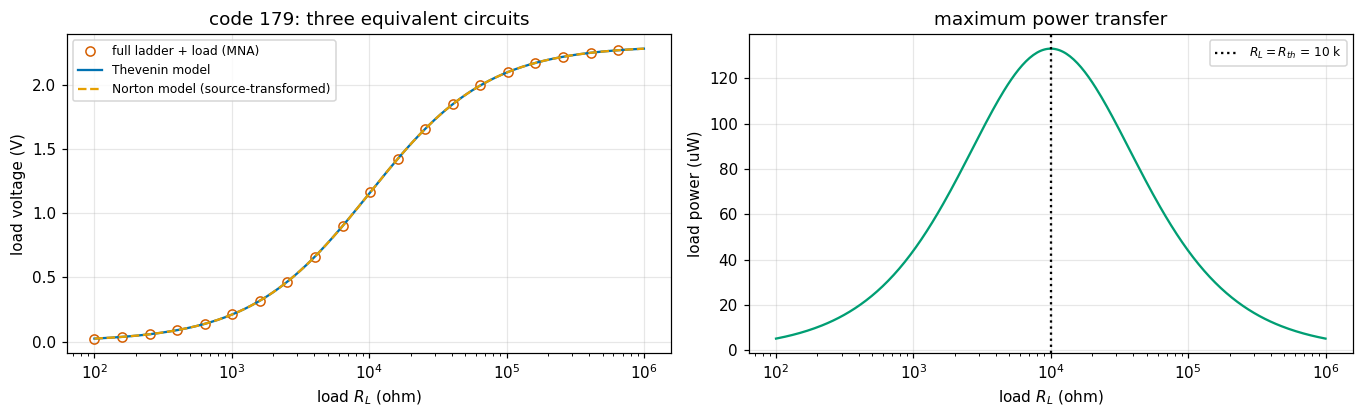

Figure 2. Left: load voltage against load resistance for code 179 from the full ladder (open red circles), the Thevenin model (solid blue), and the Norton model obtained by source transformation (dashed orange); all three coincide. Right: power into the load (solid green) peaks at R_L = R_th = 10 k (dotted line) at V_th^2/(4 R_th) = 133.1 uW. Maximum power is the wrong goal for a DAC, though: at that load the output is halved. For voltage accuracy you want R_L >> R_th.


In [4]:
rows = []
for code_ in (0, 1, 2, 64, 128, 179, 255):
    els, n_, o_ = c.r2r_netlist(code_, N, R, VREF)
    v_, r_, i_ = c.thevenin(els, n_, o_)
    rows.append(dict(code=code_, V_th=v_, R_th_ohm=r_, I_N_A=i_, V_th_over_R_th=v_/r_))
display(pd.DataFrame(rows))
code1 = 179
els, n_, o_ = c.r2r_netlist(code1, N, R, VREF)
vth, rth, iN = c.thevenin(els, n_, o_)
RL = np.logspace(2, 6, 300)
P = c.load_power(vth, rth, RL)
v_full = [c.node_voltage(els + [('R', o_, 0, rl)], n_, o_) for rl in RL[::15]]
vt2, rt2 = c.norton_to_thevenin(*c.thevenin_to_norton(vth, rth))
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
ax[0].semilogx(RL[::15], v_full, 'o', mfc='none', color=OI['red'], label='full ladder + load (MNA)')
ax[0].semilogx(RL, vth*RL/(rth + RL), '-', color=OI['blue'], label='Thevenin model')
ax[0].semilogx(RL, iN*(rth*RL/(rth + RL)), '--', color=OI['orange'], label='Norton model (source-transformed)')
ax[0].set(xlabel='load $R_L$ (ohm)', ylabel='load voltage (V)', title=f'code {code1}: three equivalent circuits'); ax[0].legend(fontsize=8)
ax[1].semilogx(RL, P*1e6, '-', color=OI['green'])
ax[1].axvline(rth, color=OI['black'], ls=':', label=f'$R_L = R_{{th}}$ = {rth/1e3:.0f} k')
ax[1].set(xlabel='load $R_L$ (ohm)', ylabel='load power (uW)', title='maximum power transfer'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 2. Left: load voltage against load resistance for code 179 from the full ladder (open red circles), the Thevenin '
      'model (solid blue), and the Norton model obtained by source transformation (dashed orange); all three coincide. Right: '
      f'power into the load (solid green) peaks at R_L = R_th = 10 k (dotted line) at V_th^2/(4 R_th) = {vth**2/(4*rth)*1e6:.1f} uW. '
      'Maximum power is the wrong goal for a DAC, though: at that load the output is halved. For voltage accuracy you want R_L >> R_th.')

## 4. Dependent source: the output buffer (4.3, 4.6)

To drive a real load without the halving above, the ladder feeds a unity-gain op-amp follower. Modeled the SPICE way, the op-amp is a voltage-controlled voltage source (VCVS) of gain $A$ with output resistance $r_o=50$ Ω driving 1 kΩ. With feedback the closed-loop gain is $A\beta/(1+A\beta)$, $\beta=R_L/(R_L+r_o)$.

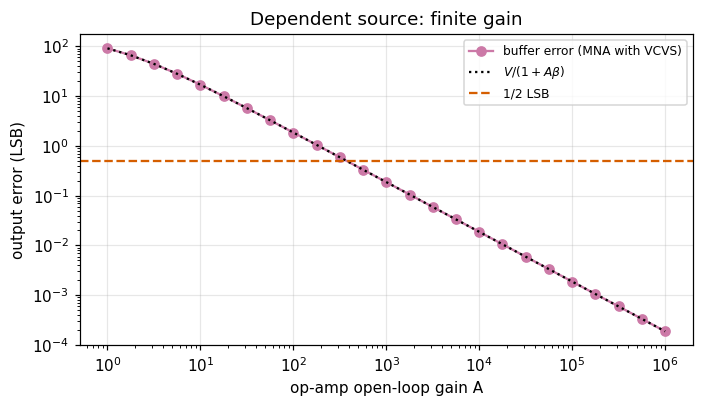

Figure 3. Error of the buffered output (purple circles, MNA with a VCVS) against open-loop gain, with the closed form V/(1 + A beta) (dotted). Staying under 1/2 LSB (dashed red) needs A of about 6e+02 or more; ordinary op-amps (~1e5) clear it easily.


In [5]:
gains = np.logspace(0, 6, 25)
err = [abs(c.buffered_output(179, gain=g_)[0] - c.dac_output(179))/LSB for g_ in gains]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.loglog(gains, err, 'o-', color=OI['purple'], label='buffer error (MNA with VCVS)')
beta = 1e3/1050
ax.loglog(gains, c.dac_output(179)/(1 + gains*beta)/LSB, ':', color=OI['black'], label='$V/(1+A\\beta)$')
ax.axhline(0.5, color=OI['red'], ls='--', label='1/2 LSB')
ax.set(xlabel='op-amp open-loop gain A', ylabel='output error (LSB)', title='Dependent source: finite gain'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
a_half = gains[np.argmax(np.array(err) < 0.5)]
print('Figure 3. Error of the buffered output (purple circles, MNA with a VCVS) against open-loop gain, with the closed form '
      f'V/(1 + A beta) (dotted). Staying under 1/2 LSB (dashed red) needs A of about {a_half:.0e} or more; ordinary op-amps (~1e5) clear it easily.')

## 5. Practical Perspective: circuits with realistic resistors (Fig. 4)

Real resistors carry a **tolerance**. Draw every one of the 16 resistors uniformly within ±tol and the steps become unequal. The figures of merit are
- **DNL:** step size minus 1 LSB. Below −1 LSB the output goes *down* when the code goes up, i.e. the DAC is non-monotonic.
- **INL:** deviation from the ideal line.

The worst step is usually at the MSB transition, 127 → 128, where every bit flips.

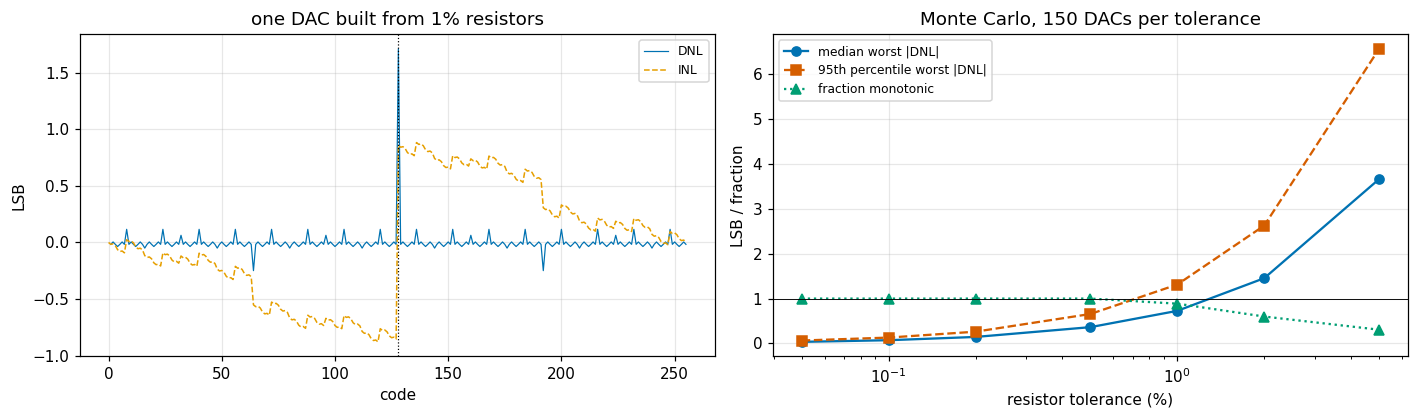

Figure 4. Left: DNL (solid blue) and INL (dashed orange) for one simulated DAC built from 1% resistors; the dotted line marks the MSB transition 127 -> 128. In this instance the largest |DNL| (1.71 LSB) is at the step into code 128. Right: Monte Carlo over 150 DACs per tolerance: median (blue circles) and 95th-percentile (red squares) worst |DNL| in LSB, and the fraction that are monotonic (green triangles). Every simulated DAC is monotonic up to 0.5% tolerance; at 1% about 89% are. That is consistent with the rule of thumb tolerance < 2^-N = 0.39% (resistor errors drawn uniformly within the tolerance).


,tolerance_pct,median_worst_DNL_LSB,p95_worst_DNL_LSB,median_worst_INL_LSB,monotonic_fraction
0,0.05,0.036,0.066,0.022,1.000
1,0.10,0.073,0.131,0.044,1.000
2,0.20,0.145,0.263,0.088,1.000
3,0.50,0.364,0.657,0.220,1.000
4,1.00,0.727,1.313,0.441,0.887
5,2.00,1.454,2.626,0.883,0.600
6,5.00,3.662,6.564,2.208,0.307


In [6]:
rng = np.random.default_rng(4)
e1 = rng.uniform(-0.01, 0.01, 2*N)
dnl, inl = c.dnl_inl(c.transfer_curve(N, R, VREF, e1))
tols = [0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05]
mc = []
for t_ in tols:
    wd, wi, mono = c.monte_carlo_tolerance(t_, n_trials=150, seed=1)
    mc.append(dict(tolerance_pct=t_*100, median_worst_DNL_LSB=np.median(wd), p95_worst_DNL_LSB=np.percentile(wd, 95),
                   median_worst_INL_LSB=np.median(wi), monotonic_fraction=mono))
mc = pd.DataFrame(mc)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
ax[0].plot(np.arange(1, 256), dnl, '-', color=OI['blue'], lw=0.8, label='DNL')
ax[0].plot(np.arange(256), inl, '--', color=OI['orange'], lw=1, label='INL')
ax[0].axvline(128, color=OI['black'], ls=':', lw=0.8)
ax[0].set(xlabel='code', ylabel='LSB', title='one DAC built from 1% resistors'); ax[0].legend(fontsize=8)
ax[1].semilogx(mc.tolerance_pct, mc.median_worst_DNL_LSB, 'o-', color=OI['blue'], label='median worst |DNL|')
ax[1].semilogx(mc.tolerance_pct, mc.p95_worst_DNL_LSB, 's--', color=OI['red'], label='95th percentile worst |DNL|')
ax[1].semilogx(mc.tolerance_pct, mc.monotonic_fraction, '^:', color=OI['green'], label='fraction monotonic')
ax[1].axhline(1, color=OI['black'], lw=0.6)
ax[1].set(xlabel='resistor tolerance (%)', ylabel='LSB / fraction', title='Monte Carlo, 150 DACs per tolerance'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
worst_step = int(np.argmax(np.abs(dnl))) + 1
all_mono = mc.tolerance_pct[mc.monotonic_fraction == 1.0].max()
print('Figure 4. Left: DNL (solid blue) and INL (dashed orange) for one simulated DAC built from 1% resistors; the dotted line '
      f'marks the MSB transition 127 -> 128. In this instance the largest |DNL| ({np.max(np.abs(dnl)):.2f} LSB) is at the step '
      f'into code {worst_step}. Right: Monte Carlo over 150 DACs per tolerance: median (blue circles) and 95th-percentile (red '
      'squares) worst |DNL| in LSB, and the fraction that are monotonic (green triangles). Every simulated DAC is monotonic up '
      f'to {all_mono:g}% tolerance; at 1% about {mc.monotonic_fraction[mc.tolerance_pct == 1.0].iloc[0]*100:.0f}% are. That is '
      'consistent with the rule of thumb tolerance < 2^-N = 0.39% (resistor errors drawn uniformly within the tolerance).')
mc.round(3)

## 6. Room temperature: thermal noise and temperature coefficient

**Johnson–Nyquist noise:** a resistor at temperature $T$ makes open-circuit noise $\sqrt{4k_BTRB}$. The ladder's noise is that of its $R_\text{th}=R$. **Tempco:** if every resistor drifts by the same fraction, the *ratios* don't change and neither does the output (the ladder is ratiometric). Only a *spread* in tempco shows up.

In [7]:
rows = []
for Rv in (1e3, 10e3, 100e3, 1e6):
    vn = c.johnson_noise_rms(Rv, 1e6)
    rows.append(dict(R_ohm=Rv, noise_uV_rms_1MHz=vn*1e6, noise_in_LSB=vn/LSB))
display(pd.DataFrame(rows))
for spread in (0, 5, 25, 100):
    shifts = [(c.dac_output(c_, N, R, VREF, c.tempco_errors(N, 100, 50, spread, seed=2)) - c.dac_output(c_, N, R, VREF))/LSB for c_ in range(256)]
    print(f'tempco 100 ppm/K common, spread {spread:3d} ppm/K, +50 K: worst output shift {np.max(np.abs(shifts)):.3f} LSB')
print('Thermal noise is ~1000x below an 8-bit LSB at 1 MHz, so at room temperature resistor MATCHING, not noise, limits this DAC.')

,R_ohm,noise_uV_rms_1MHz,noise_in_LSB
0,1000.0,4.070355,0.000316
1,10000.0,12.871592,0.000999
2,100000.0,40.703548,0.003158
3,1000000.0,128.715920,0.009985


tempco 100 ppm/K common, spread   0 ppm/K, +50 K: worst output shift 0.000 LSB
tempco 100 ppm/K common, spread   5 ppm/K, +50 K: worst output shift 0.015 LSB
tempco 100 ppm/K common, spread  25 ppm/K, +50 K: worst output shift 0.075 LSB
tempco 100 ppm/K common, spread 100 ppm/K, +50 K: worst output shift 0.298 LSB
Thermal noise is ~1000x below an 8-bit LSB at 1 MHz, so at room temperature resistor MATCHING, not noise, limits this DAC.


## 7. The bench: function generator and oscilloscope (Fig. 5)

* **A function generator is a Thévenin source** with $R_\text{th}=50$ Ω. Its amplitude knob assumes a 50 Ω load, so internally $V_\text{th}=2V_\text{set}$. Into a 1 MΩ scope the screen shows **about twice** the setting. That's what the generator's "High-Z" setting is for.
* **The scope is a load:** 1 MΩ ∥ ~15 pF. On the DAC ($R_\text{th}=10$ kΩ) the DC reading is low by $R_\text{th}/(R_\text{th}+1\,\text{M}\Omega)$. With the 15 pF, the ladder's output becomes an RC low-pass, $f_{3\text{dB}}=1/(2\pi R_\text{th}C)$.

,setting_Vpp,load,actual_Vpp
0,1.0,50 ohm (as the display assumes),1.0000
1,1.0,1 Mohm scope input,1.9999


R-2R with R =     1 k: 1 Mohm scope reads   0.26 LSB low at full scale; with 15 pF, f_3dB =  10.61 MHz
R-2R with R =    10 k: 1 Mohm scope reads   2.53 LSB low at full scale; with 15 pF, f_3dB =   1.06 MHz
R-2R with R =   100 k: 1 Mohm scope reads  23.27 LSB low at full scale; with 15 pF, f_3dB =   0.11 MHz


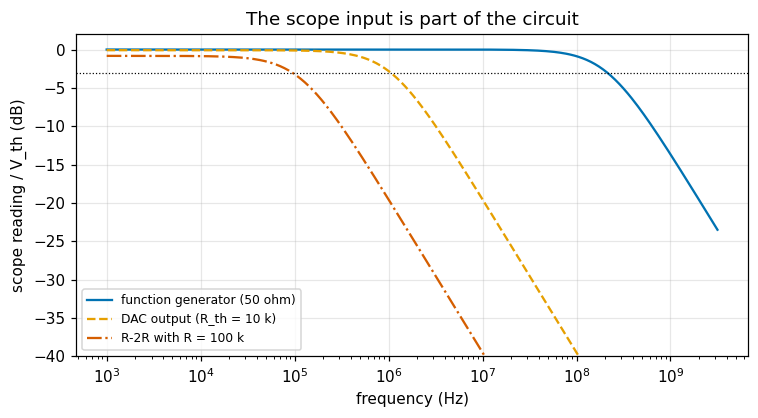

Figure 5. Scope reading relative to the source Thevenin voltage against frequency (dgs.spice s-domain MNA with the scope modelled as 1 Mohm || 15 pF). The 50 ohm generator (solid blue) is flat to ~212 MHz; the 10 k DAC output (dashed orange) rolls off at ~1 MHz and a 100 k ladder (dash-dot red) at ~106 kHz (dotted line = -3 dB). The source resistance sets the measurement bandwidth: another reason to buffer the DAC (Sec. 4).


In [8]:
rows = [dict(setting_Vpp=1.0, load='50 ohm (as the display assumes)', actual_Vpp=c.fgen_into_load(1.0, 50)),
        dict(setting_Vpp=1.0, load='1 Mohm scope input', actual_Vpp=c.fgen_into_load(1.0, 1e6))]
display(pd.DataFrame(rows))
for Rv in (1e3, 10e3, 100e3):
    print(f'R-2R with R = {Rv/1e3:5.0f} k: 1 Mohm scope reads {c.scope_loading_error(Rv)*256:6.2f} LSB low at full scale; '
          f'with 15 pF, f_3dB = {1/(2*np.pi*Rv*15e-12)/1e6:6.2f} MHz')
f = np.logspace(3, 9.5, 300)
fig, ax = plt.subplots(figsize=(7, 3.9))
for rs, c_, ls, lab in [(50.0, OI['blue'], '-', 'function generator (50 ohm)'), (10e3, OI['orange'], '--', 'DAC output (R_th = 10 k)'), (100e3, OI['red'], '-.', 'R-2R with R = 100 k')]:
    ax.semilogx(f, 20*np.log10(c.scope_frequency_response(f, rs)), ls, color=c_, label=lab)
ax.axhline(-3, color=OI['black'], ls=':', lw=0.8)
ax.set(xlabel='frequency (Hz)', ylabel='scope reading / V_th (dB)', ylim=(-40, 2), title='The scope input is part of the circuit'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 5. Scope reading relative to the source Thevenin voltage against frequency (dgs.spice s-domain MNA with the scope '
      'modelled as 1 Mohm || 15 pF). The 50 ohm generator (solid blue) is flat to ~212 MHz; the 10 k DAC output (dashed orange) '
      'rolls off at ~1 MHz and a 100 k ladder (dash-dot red) at ~106 kHz (dotted line = -3 dB). The source resistance sets the '
      'measurement bandwidth: another reason to buffer the DAC (Sec. 4).')

## 8. Research direction you mentioned: PhyCV in CUDA

`dgs/phase_stretch_crack_detection.py` already wraps Jalali's **PhyCV** Phase Stretch Transform. PST is the same pipeline as this repo's dispersion operator: FFT → multiply by a phase kernel $e^{i\phi(\nu)}$ → inverse FFT → take the phase. That is exactly what `dgs/gs_cuda.py` (CuPy) already runs on the RTX 4060. A CUDA/CuPy PST is therefore mostly a kernel swap on existing GPU code.
1. Check what PhyCV's own GPU classes already cover; from memory it has PyTorch versions, so verify on its GitHub.
2. Time CPU vs GPU across image sizes and fit the cost per pixel with the same regression method as `rigid_body_harsh.ipynb`.
3. Validate pixel-for-pixel against PhyCV.

**References** (from memory; verify before citing)
[1] J. W. Nilsson and S. A. Riedel, *Electric Circuits*, ch. 4 "Techniques of Circuit Analysis." Hoboken, NJ, USA: Pearson.
[2] J. B. Johnson, "Thermal agitation of electricity in conductors," *Phys. Rev.*, vol. 32, no. 1, pp. 97–109, 1928.
[3] H. Nyquist, "Thermal agitation of electric charge in conductors," *Phys. Rev.*, vol. 32, no. 1, pp. 110–113, 1928.
[4] W. Kester, Ed., *Data Conversion Handbook*. Burlington, MA, USA: Newnes/Analog Devices, 2005.
[5] Y. Zhou, C. MacPhee, M. Suthar, and B. Jalali, "PhyCV: The first physics-inspired computer vision library," *arXiv:2301.12531*, 2023.

**Limitations.**
- Ideal switches (0 Ω): real CMOS switches add their on-resistance to each leg.
- Resistor errors are uniform within the tolerance.
- The op-amp model has finite gain only, with no offset or bandwidth limit.
- Scope probes, cables and the generator's own bandwidth are ignored.
- Component values are typical assumptions.